# Lab 1.5 · Causal attention

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

Attention uses a **query** to ask what information is relevant, a **key** to score how well each source position matches, and a **value** to supply the information to mix. For one query, take its dot product with each key and divide by the square root of the key width. Softmax turns the resulting scores into nonnegative weights that sum to one.

For query `[1, 0]` and keys `[1, 0]` and `[0, 1]`, the scaled scores are about `[0.707, 0]`. If both keys are visible, the weights are about `[0.67, 0.33]`. With values `[3, 0]` and `[0, 6]`, the weighted output is about `[2.01, 1.98]`.

**Causal** attention means position i can read positions up to and including i. For the first query in the example, masking the second score before softmax gives weights `[1, 0]` and output `[3, 0]`. The notebook holds queries, keys, and values fixed so you can isolate what scoring and masking do. In a model, learned projections produce these vectors. Self-attention projects them from the same sequence. Cross-attention takes queries from one sequence and keys and values from another.

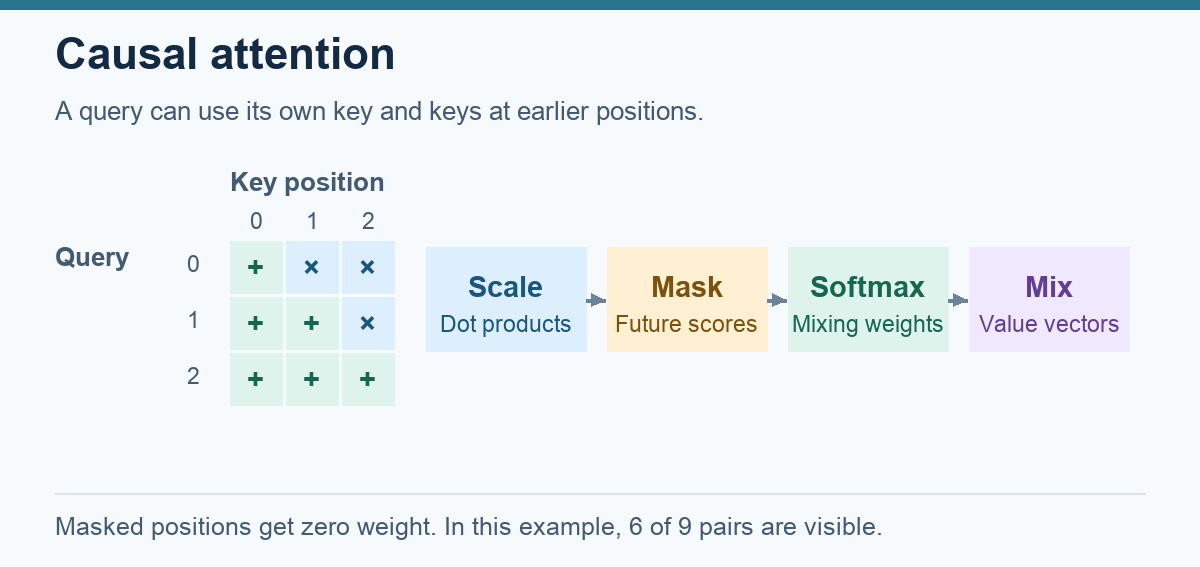

## Exercise map

1. **Score and mask keys** — Compute one scaled dot product per key. Use negative infinity for future keys when the causal mask is enabled.
2. **Mix values and test causality** — Use the weights to build the output vector, then change only the final value and compare masked and unmasked runs.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
from math import exp, isclose, sqrt

queries = [[1, 0], [1, 0], [0, 1]]
keys = [[1, 0], [0, 1], [2, 1]]
values = [[1, 0], [0, 2], [3, 3]]

def attention_weights(scores):
    shifted = [exp(score - max(scores)) for score in scores]
    total = sum(shifted)
    return [weight / total for weight in shifted]

## Exercise 1. Score and mask keys

For query index i and key index j, compute their dot product divided by the square root of the key width. If causal masking is on and j is greater than i, use negative infinity.

**Implementation hint** — Compare the key index j with the query index i before returning a score. The scale depends on the key vector width.

**After running the check** — Inspect the first softmax row. The first position can only attend to itself, so all weight goes to that key.

In [ ]:
def score_row(i, queries, keys, causal):
    return None

In [ ]:
scores = score_row(0, queries, keys, True)
if scores is not None:
    assert isclose(scores[0], 1 / sqrt(2))
    assert scores[1:] == [float("-inf")] * 2
    assert all(score != float("-inf") for score in score_row(0, queries, keys, False))
    print("PASS — first weight row:", attention_weights(scores))

### Read the result

Check visibility before interpreting the output. A future key should have zero probability after masking and softmax.

## Exercise 2. Mix values and test causality

Compute a weighted sum for each value feature. Then compare the output with the causal mask on and off. Predict which rows change when only the final value vector changes.

**Implementation hint** — For a given output feature, sum weight[j] times the same feature of value row j across source positions.

**After running the check** — With masking, the final value can affect the last output, while earlier outputs stay fixed. The unmasked run provides a comparison.

In [ ]:
def mix_values(weights, values):
    return None

In [ ]:
check_passed = False
if scores is not None and mix_values([1, 0, 0], values) is not None:
    def attention(values, causal):
        weights = [attention_weights(score_row(i, queries, keys, causal))
                   for i in range(len(queries))]
        assert all(isclose(sum(row), 1.0) for row in weights)
        return weights, [mix_values(row, values) for row in weights]

    masked_weights, masked = attention(values, True)
    _, unmasked = attention(values, False)
    changed = [*values[:-1], [30, 30]]
    _, masked_changed = attention(changed, True)
    _, unmasked_changed = attention(changed, False)
    assert masked[0] == values[0]
    assert masked_changed[:2] == masked[:2] and masked_changed[2] != masked[2]
    assert unmasked_changed[0] != unmasked[0]
    pairs = [(i, j) for i, row in enumerate(masked_weights) for j, w in enumerate(row) if w > 0]
    print("Visible query-key pairs:", len(pairs), "of", len(queries) * len(keys))
    for row in masked_weights:
        print([round(w, 3) for w in row])
    print("PASS — early causal outputs ignore future values")
    check_passed = True
if not check_passed:
    print("Complete score_row and mix_values and rerun the checks in order.")

### Read the result

Change the last value and inspect earlier rows. Their exact match is evidence that future values cannot leak into them.

## Compare your results

![Follow the weight, then the value. Score: [0.707, 0]. Scaled matches for one query; Mask + softmax: [1, 0]. Remove the future key; Value mix: [3, 0]. All weight on the first value.](attachment:result-preview.png)
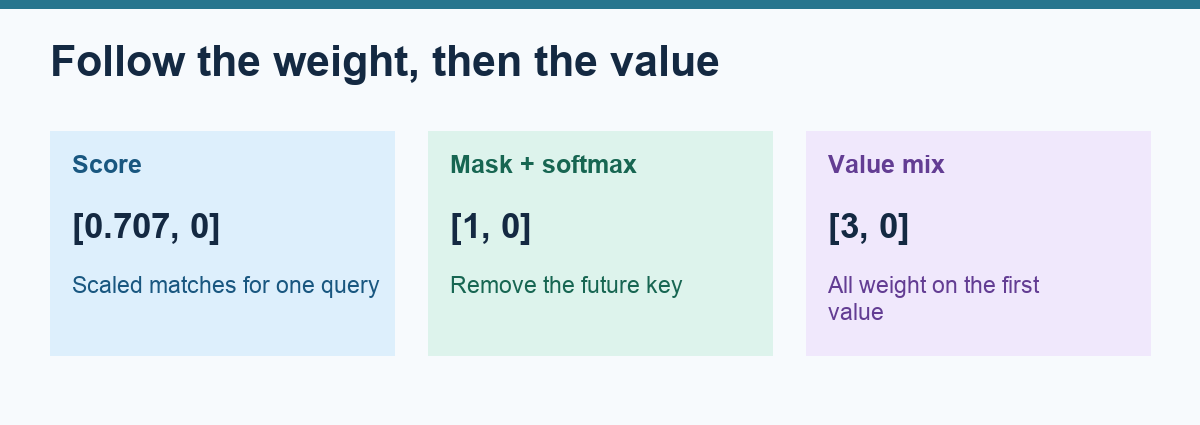

## Optional extension · Prefill versus cached decode attention

Kiely distinguishes self-attention from cross-attention and connects the KV cache to repeated decoding. This lab uses causal self-attention. For a length-L prompt, the causal mask allows L(L+1)/2 query-key pairs during prefill. A single subsequent decode query can attend to L cached keys and its own new key, so that step has L+1 pairs. These are logical counts. A kernel can perform a different amount of work.

Double the prompt length from 4 to 8. Compare how the visible prefill pairs and the pairs for one cached decode query grow.

**Reading** · Philip Kiely, *Inference Engineering*, §2.2.3, pp. 52–53.

In [ ]:
for length in (4, 8):
    prefill_pairs = sum(range(1, length + 1))
    decode_pairs = length + 1
    print(length, "prompt positions:", prefill_pairs, "prefill,", decode_pairs, "decode")
assert sum(range(1, 9)) == 36

## Wrap-up

In a new cell, append a fourth query and key. Use `score_row` and `attention_weights` to count the visible pairs again. Predict the new count before running that cell. Does a causal mask alone save dot products in every attention implementation?

## Optional system exercise · Causality as an output invariant

At fixed head width, one cached decode query scores a number of keys proportional to the current context length. For a prompt of P tokens and G decode queries, the total number of pairs across decode is GP + G(G+1)/2. The cache saves recomputing earlier key and value projections, while the context still grows.

Repeat the future-value perturbation with a larger magnitude and verify that earlier causal outputs are still unchanged. Explain why this is a stronger check than verifying only that each probability row sums to one.